# How to use viewmastR

viewmastR predicts the cell types of a query dataset from a labelled reference. This
tutorial installs the package, selects shared variable genes, trains a model, and checks
its predictions. It follows the R article
[How to use viewmastR](https://furlan-lab.github.io/viewmastR/articles/HowTo.html).

| Role | Dataset |
|---|---|
| Reference | healthy bone marrow atlas (Granja et al. 2019, "Greenleaf reference") |
| Query | T-cell-depleted bone marrow, multiome RNA, 8,627 cells with the authors' labels and UMAP (Persad et al. 2023; the file the [Mellon](https://github.com/settylab/Mellon) tutorial uses) |

## Install

```bash
uv pip install "git+https://github.com/jacob-greene/py-viewmastR"
```

A Rust toolchain (1.86 or newer) builds the burn backend during the install.

## Load the data

Copy `data_paths.example.json` to `data_paths.json` and set the reference path. The query
downloads on first use (2.5 GB). It is used as published: raw counts, the authors' labels
and their UMAP. Nothing is re-normalised or re-embedded.

In [1]:
import matplotlib.pyplot as plt
import scanpy as sc
import viewmastr as vm
import tutorial_data as td

sc.set_figure_params(dpi=80, frameon=False)
label = td.config().get("greenleaf_label", "celltype")
ref = td.greenleaf_reference()
query = td.bm_tcelldep()
print(ref.shape, query.shape)

(36318, 20287) (8627, 17226)


## The query's own labels

The authors' labels use different names from the reference, but they show which
populations to expect. The UMAP is the one stored in the file; viewmastR does not use it.
`vm.palette` gives every cell type the same colour in every figure.

celltype
Mono          4665
NaiveB         976
MonoPre        645
EryPre2        326
EryPre1        315
cDC            296
preB           217
MyeloidPre     186
Ery            157
proB           155
pDC            131
MylEry         122
HMP            121
MEP             99
HSC             95
preproB         59
CLP             38
Mega            24


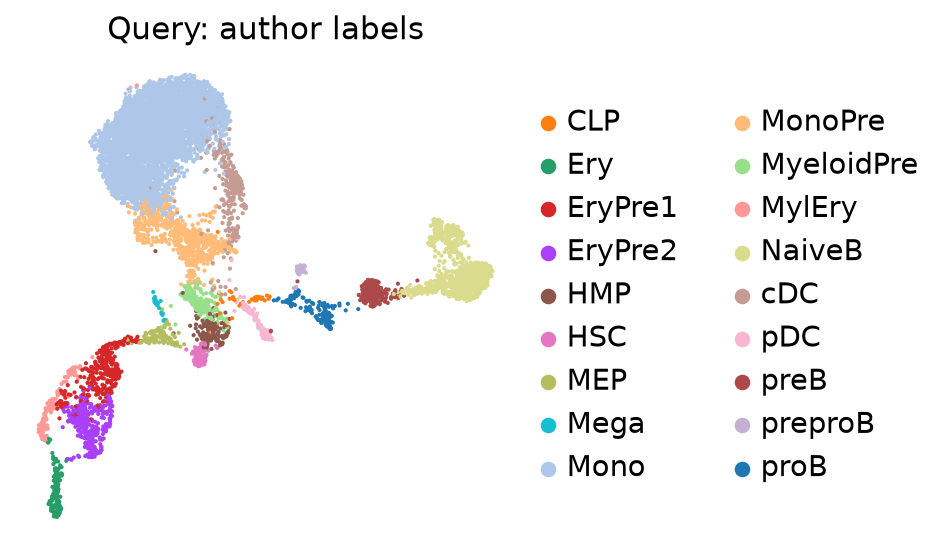

In [2]:
vm.palette.set_colors(query, "celltype")
print(query.obs["celltype"].value_counts().to_string())
sc.pl.umap(query, color="celltype", title="Query: author labels")

## Find shared variable genes

viewmastR works best on genes that vary in both datasets. For each dataset, compute the
per-gene dispersion, keep the 10,000 most dispersed genes in a mean-expression window, and
intersect the two lists. Selected genes are red; the line is the fitted mean-dispersion trend.

4860 shared variable genes


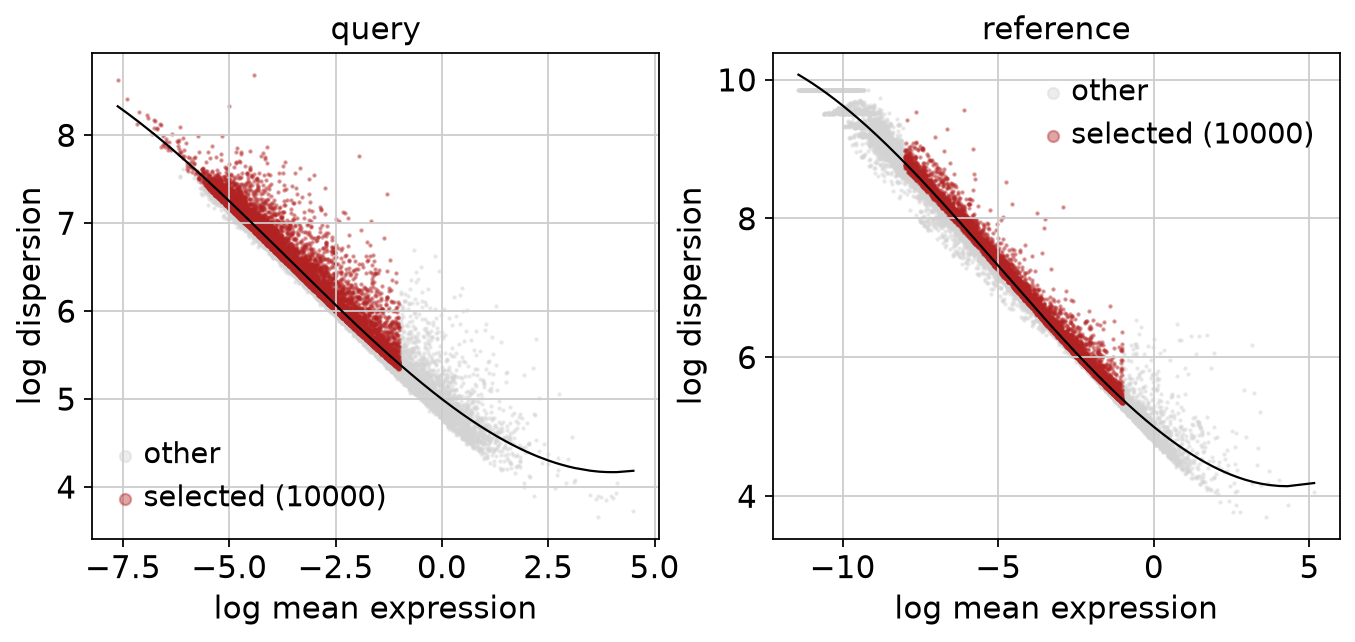

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, a) in zip(axes, [("query", query), ("reference", ref)]):
    vm.calculate_feature_dispersion(a)
    vm.select_features(a, top_n=10_000, logmean_ul=-1, logmean_ll=-8)
    vm.plot_feature_dispersion(a, ax=ax).set_title(name)
vgr = set(vm.get_selected_features(ref))
vg = [g for g in vm.get_selected_features(query) if g in vgr]
print(f"{len(vg)} shared variable genes")

## The reference cell types

These are the labels viewmastR learns.

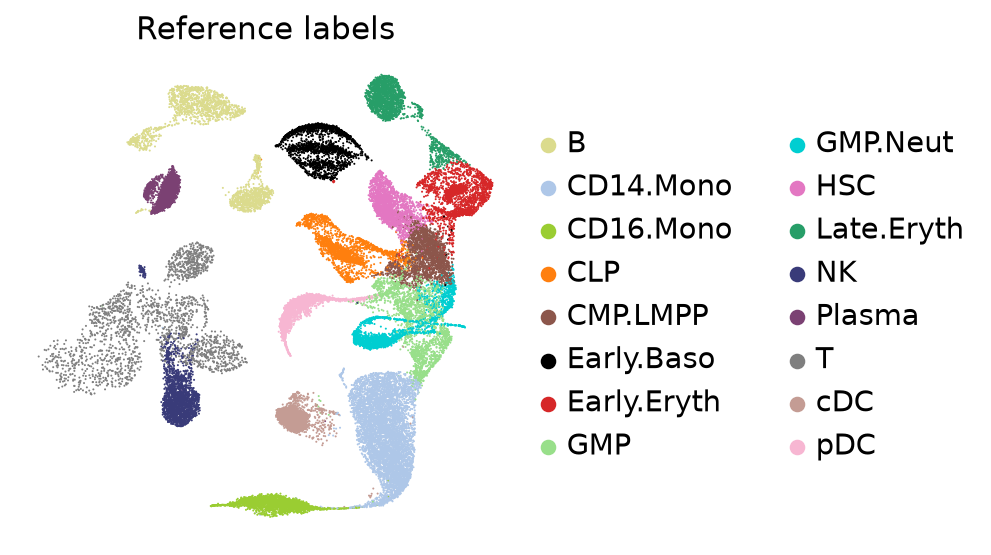

In [4]:
vm.palette.set_colors(ref, label)
sc.pl.umap(ref, color=label, title="Reference labels")

## Run viewmastR

`viewmastR()` trains on the reference and writes the prediction to
`query.obs["viewmastR_pred"]`.

viewmastR: 4860 features, 16 classes, 29054 train / 7264 test cells


[epoch 1 | train accuracy 85.358% | validation accuracy 94.411%]


[epoch 2 | train accuracy 96.063% | validation accuracy 95.127%]


[epoch 3 | train accuracy 97.016% | validation accuracy 95.443%]


[epoch 4 | train accuracy 97.680% | validation accuracy 95.567%]


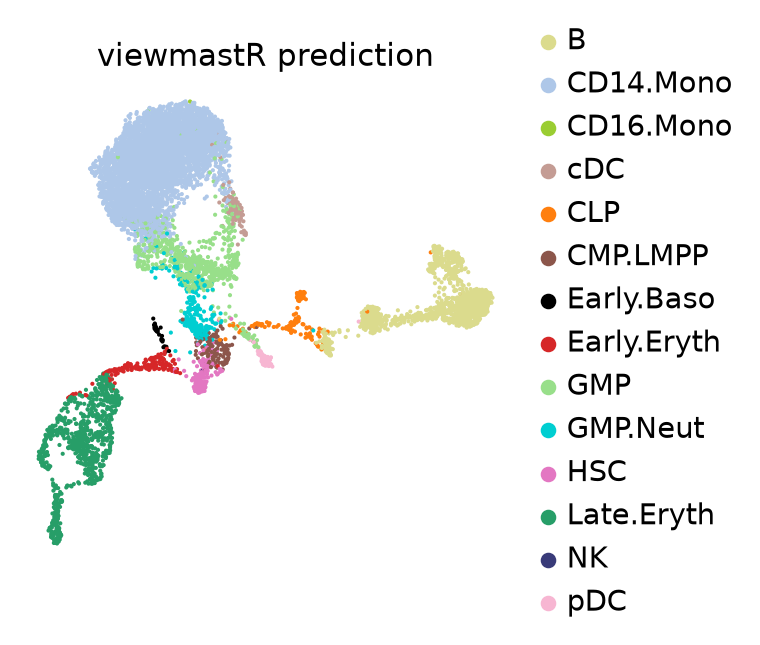

In [5]:
vm.viewmastR(query, ref, label, selected_features=vg, max_epochs=4)
vm.palette.set_colors(query, "viewmastR_pred")
sc.pl.umap(query, color="viewmastR_pred", title="viewmastR prediction")

## Compare with the author labels

Columns are the author labels; rows are the predictions; colour is the percent of each
column. The two vocabularies differ, so read this as a mapping, not an accuracy: for
example, the author `Mono` cells should map to reference monocytes.

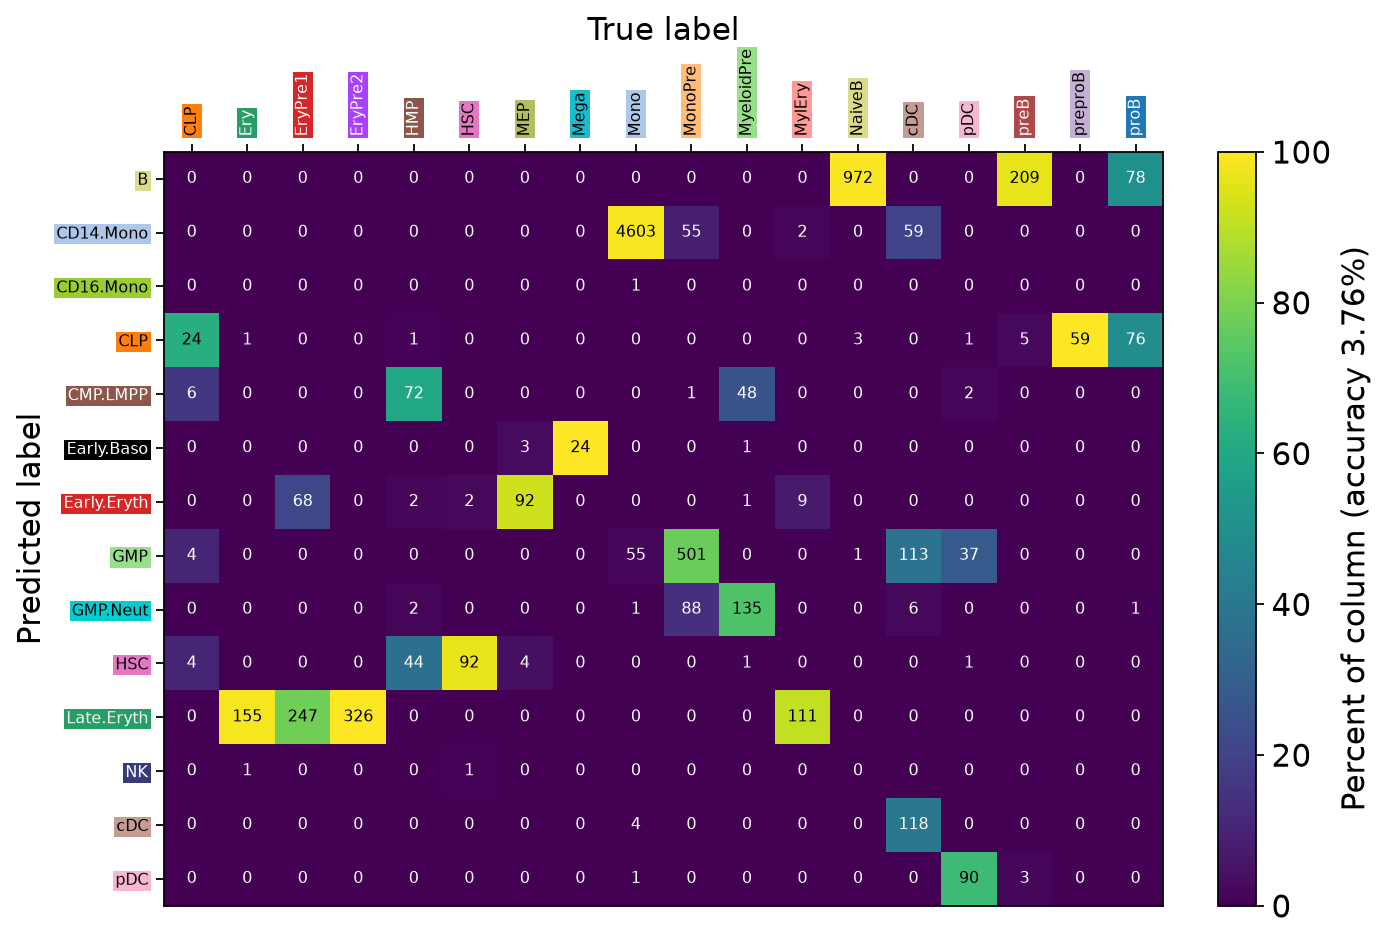

In [6]:
vm.confusion_matrix(query.obs["viewmastR_pred"], query.obs["celltype"],
                    cols=vm.palette.colors([*query.obs["viewmastR_pred"], *query.obs["celltype"]]))
plt.show()

## Training history

`return_type="list"` also returns the per-epoch accuracy and loss. If training loss keeps
falling while validation loss rises, the model over-fits.

viewmastR: 4860 features, 16 classes, 29054 train / 7264 test cells


[epoch 1 | train accuracy 85.868% | validation accuracy 95.113%]


[epoch 2 | train accuracy 95.990% | validation accuracy 95.705%]


[epoch 3 | train accuracy 96.992% | validation accuracy 95.843%]


[epoch 4 | train accuracy 97.615% | validation accuracy 95.980%]


[epoch 5 | train accuracy 98.159% | validation accuracy 96.132%]


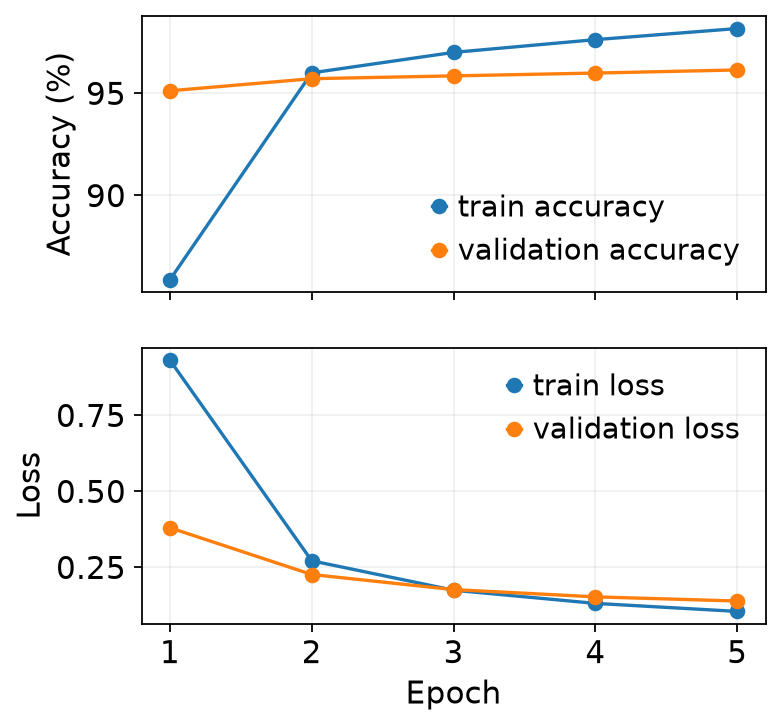

In [7]:
res = vm.viewmastR(query, ref, label, selected_features=vg, return_type="list")
vm.plot_training_data(res)
plt.show()

## Probabilities

`return_probs=True` adds one `prob_<label>` column per class: the softmax of the model's
log-odds.

viewmastR: 4860 features, 16 classes, 29054 train / 7264 test cells


[epoch 1 | train accuracy 86.931% | validation accuracy 94.686%]


[epoch 2 | train accuracy 96.114% | validation accuracy 95.374%]


[epoch 3 | train accuracy 96.961% | validation accuracy 95.540%]


[epoch 4 | train accuracy 97.615% | validation accuracy 95.815%]


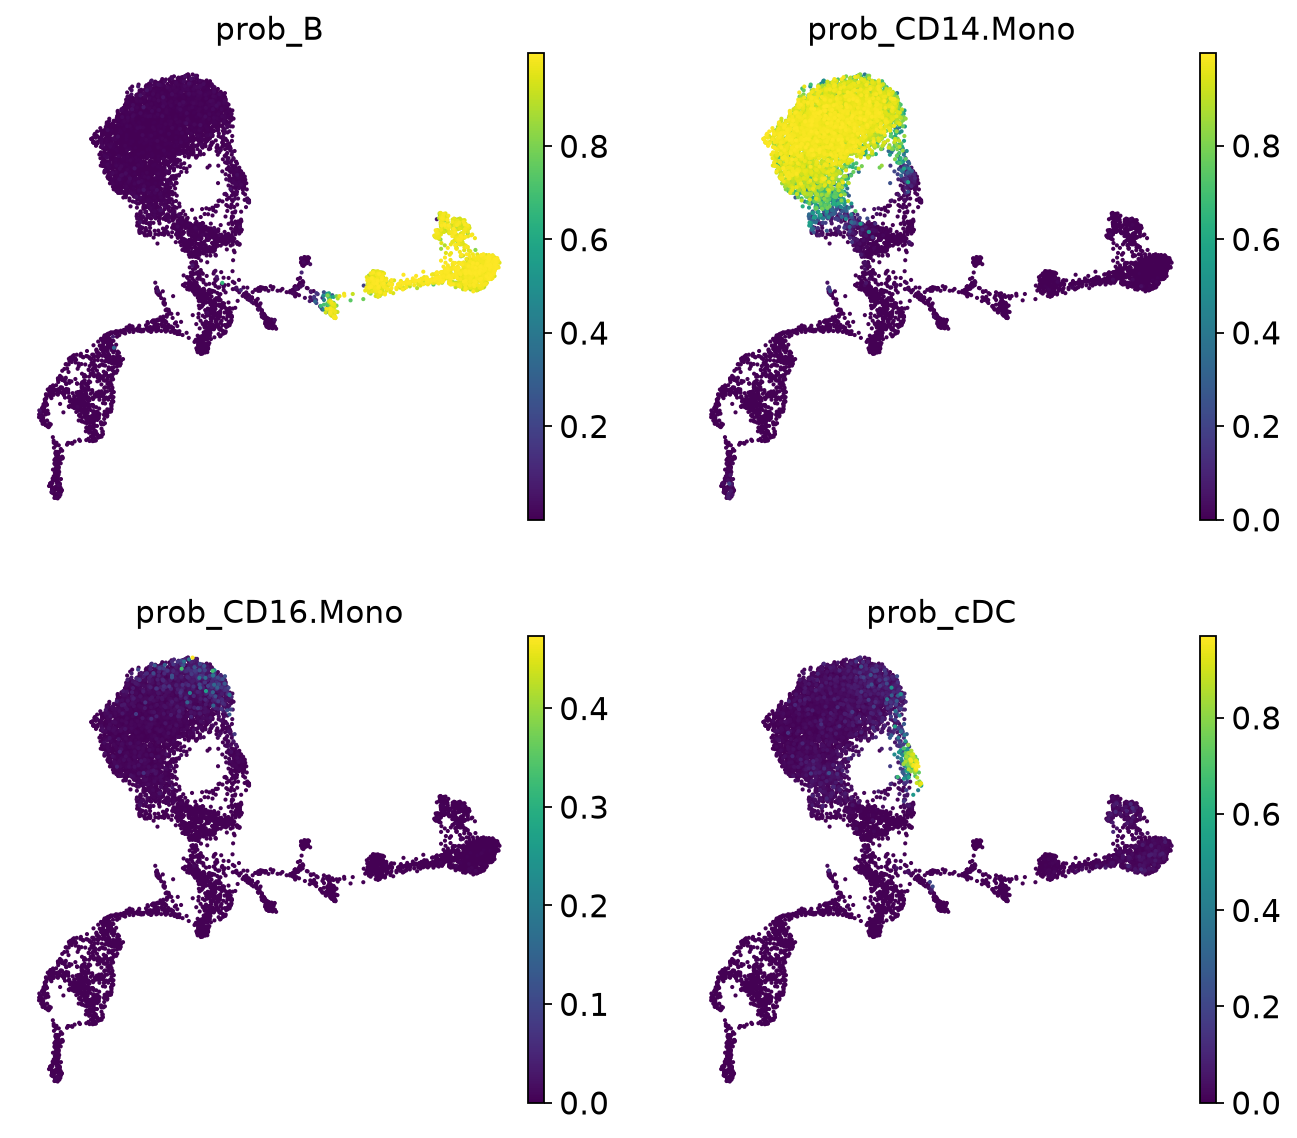

In [8]:
vm.viewmastR(query, ref, label, selected_features=vg, max_epochs=4, return_probs=True)
prob_cols = [c for c in query.obs if c.startswith("prob_")]
sc.pl.umap(query, color=prob_cols[:4], ncols=2, cmap="viridis")

## Versions

In [9]:
from importlib.metadata import version
for pkg in ("viewmastr", "scanpy", "anndata", "numpy", "scipy"):
    print(f"{pkg:10s} {version(pkg)}")

viewmastr  0.1.0
scanpy     1.12.5
anndata    0.13.4
numpy      2.5.4
scipy      1.18.1
